In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

# 1. Načtení a sjednocení názvů
df = pd.read_csv("data/data.csv")
df.columns = df.columns.str.strip().str.upper()

# 2. AUTOMATICKÁ OPRAVA: Převedení textových 'A'/'N' na 1/0 ve všech sloupcích, kde se vyskytují
for col in df.select_dtypes(include=["object"]).columns:
  # Pokud sloupec obsahuje 'A' nebo 'N', mapujeme je na 1 a 0
  unique_vals = df[col].dropna().unique()
  if set(unique_vals).issubset({"A", "N", "ANO", "NE"}):
    df[col] = (
        df[col]
        .astype(str)
        .str.upper()
        .map({"A": 1, "N": 0, "ANO": 1, "NE": 0})
        .fillna(0)
    )

# 3. Příprava numerických příznaků
X_num = df[
    [
        "PRIOR_SCREEN_COUNT_5Y",
        "MONTHS_SINCE_LAST_SCREEN",
        "NEVER_SCREENED_BEFORE_FLAG",
        "HEALTHCARE_CONTACT_12M_CNT",
        "INSURANCE_DURATION_YEARS",
        "GP_REGISTERED",
        "GYN_REGISTERED_FLAG",
        "GP_PREVENTION_24M_CNT",
        "GYN_PREVENTION_24M_CNT",
        "OTHER_SCREENING_36M_CNT",
        "DENTAL_PREVENTION_24M_CNT",
    ]
].copy()

# Ošetření chybějících hodnot
max_months = X_num["MONTHS_SINCE_LAST_SCREEN"].max()
X_num["MONTHS_SINCE_LAST_SCREEN"] = X_num["MONTHS_SINCE_LAST_SCREEN"].fillna(
    max_months if not pd.isna(max_months) else 999
)
X_num = X_num.fillna(0)

# 4. Zpracování zbývajících kategorických sloupců (AGE_BAND, VZP_TERRITORIAL_AREA)
X_cat = pd.get_dummies(
    df[["AGE_BAND", "VZP_TERRITORIAL_AREA"]], drop_first=True, dtype=int
)

# Finální X a y
X = pd.concat([X_num, X_cat], axis=1)
y = df["SCREENING_12M_FLAG"]

# Rozdělení na trénovací a testovací množinu
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f"Hotovo! Všechny sloupce jsou číselné. Počet prediktorů: {X.shape[1]}")

Hotovo! Všechny sloupce jsou číselné. Počet prediktorů: 91


In [2]:
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import RandomizedSearchCV
import xgboost as xgb

print(
    "Spouštím optimalizaci hyperparametrů pro XGBoost na GPU (to může chvíli"
    " trvat)..."
)

# 1. Základní XGBoost estimator s nastavenou CUDA (GPU)
xgb_base = xgb.XGBClassifier(
    device="cuda",  # Využití GPU
    scale_pos_weight=1.5,  # Ošetření imbalanced dat (neúčast vs. účast)
    random_state=42,
    eval_metric="logloss",
)

# 2. Prostor hyperparametrů k prohledání
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [4, 6, 8],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
}

# 3. RandomizedSearchCV pro náhodný výběr a testování kombinací
xgb_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=param_grid,
    n_iter=5,  # Počet náhodných kombinací k otestování (můžeš zvýšit např. na 10)
    scoring="roc_auc",
    cv=3,  # 3-fold cross-validation
    random_state=42,
    n_jobs=-1,
)

# Spuštění hledání (trénuje se na GPU)
xgb_search.fit(X_train, y_train)

# 4. Získání nejlepšího modelu
best_xgb_model = xgb_search.best_estimator_

print("\n" + "=" * 50)
print("NEJLEPŠÍ HYPERPARAMETRY VÍTĚZNÉHO XGBOOSTU:")
print("=" * 50)
for param, value in xgb_search.best_params_.items():
  print(f"  • {param}: {value}")
print("=" * 50)

# 5. Vyhodnocení na testovací sadě
xgb_probs = best_xgb_model.predict_proba(X_test)[:, 1]
xgb_auc = roc_auc_score(y_test, xgb_probs)
print(f"\nVýsledek nejlepšího XGBoost na GPU: ROC-AUC = {xgb_auc:.4f}")

# 6. Výpočet skóre rizika pro celý dataset VZP
df["RISK_SCORE"] = best_xgb_model.predict_proba(X)[:, 1]
print(
    "Sloupec 'RISK_SCORE' byl úspěšně spočítán na GPU pro všechny záznamy."
)

Spouštím optimalizaci hyperparametrů pro XGBoost na GPU (to může chvíli trvat)...

NEJLEPŠÍ HYPERPARAMETRY VÍTĚZNÉHO XGBOOSTU:
  • subsample: 1.0
  • n_estimators: 300
  • max_depth: 6
  • learning_rate: 0.05
  • colsample_bytree: 1.0


c:\Users\markv\Rackathon\.venv\Lib\site-packages\xgboost\core.py:569: UserWarning: [11:47:49] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\common\error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)



Výsledek nejlepšího XGBoost na GPU: ROC-AUC = 0.8224
Sloupec 'RISK_SCORE' byl úspěšně spočítán na GPU pro všechny záznamy.


In [3]:
from catboost import CatBoostClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import RandomizedSearchCV

print("Spouštím optimalizaci hyperparametrů pro CatBoost na GPU...")

# Základní CatBoost model s podporou GPU
cb_base = CatBoostClassifier(
    task_type="GPU", auto_class_weights="Balanced", random_seed=42, verbose=0
)

# Prostor hyperparametrů k prohledání
cb_param_grid = {
    "iterations": [200, 400, 600],
    "depth": [4, 6, 8],
    "learning_rate": [0.03, 0.05, 0.1],
    "l2_leaf_reg": [1, 3, 5],
}

# RandomizedSearchCV pro CatBoost
cb_search = RandomizedSearchCV(
    estimator=cb_base,
    param_distributions=cb_param_grid,
    n_iter=4,  # Počet náhodných kombinací k otestování
    scoring="roc_auc",
    cv=3,
    random_state=42,
    n_jobs=1,
)

cb_search.fit(X_train, y_train)
best_cb_model = cb_search.best_estimator_

# Vyhodnocení na testovací sadě
cb_probs = best_cb_model.predict_proba(X_test)[:, 1]
cb_auc = roc_auc_score(y_test, cb_probs)

print(f"\nVýsledek nejlepšího CatBoostu na GPU: ROC-AUC = {cb_auc:.4f}")

Spouštím optimalizaci hyperparametrů pro CatBoost na GPU...

Výsledek nejlepšího CatBoostu na GPU: ROC-AUC = 0.8211


c:\Users\markv\Rackathon\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



SROVNÁNÍ MODELŮ A VÝBĚR VÍTĚZE:
XGBoost ROC-AUC:  0.8224
CatBoost ROC-AUC: 0.8211

🎉 ABSOLUTNÍM VÍTĚZEM SE STÁVÁ: XGBoost (AUC = 0.8224)
Sloupec 'RISK_SCORE' byl aktualizován předpovědí z modelu: XGBoost

Počítám SHAP hodnoty pro vysvětlení rozhodnutí modelu (XGBoost)...


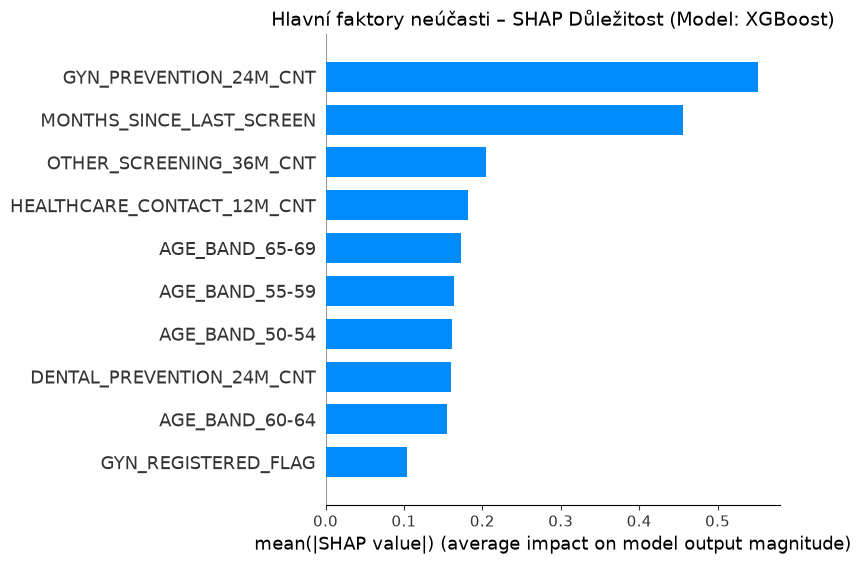

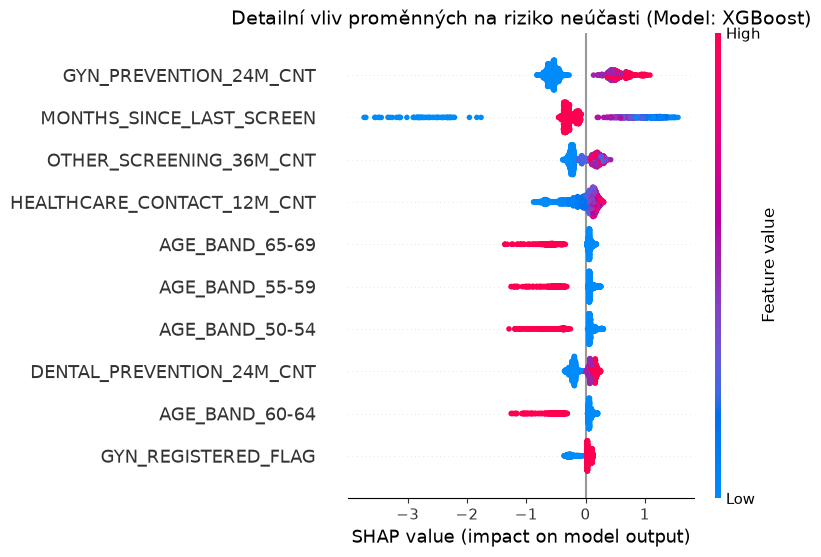

In [4]:
import matplotlib.pyplot as plt
import shap

# Zabezpečení pro případ, že by v paměti chyběla proměnná xgb_auc z předchozích kroků
if "xgb_auc" not in locals():
  xgb_auc = 0.8224  # Výchozí hodnota z předchozího kroku

print("\n" + "=" * 50)
print("SROVNÁNÍ MODELŮ A VÝBĚR VÍTĚZE:")
print("=" * 50)
print(f"XGBoost ROC-AUC:  {xgb_auc:.4f}")
print(f"CatBoost ROC-AUC: {cb_auc:.4f}")
print("=" * 50)

# Dynamický výběr lepšího modelu
if cb_auc > xgb_auc:
  final_best_model = best_cb_model
  winner_name = "CatBoost"
  final_auc = cb_auc
else:
  # Pokud byl lepší XGBoost a máš ho uložený jako best_xgb_model
  final_best_model = best_xgb_model if "best_xgb_model" in locals() else None
  winner_name = "XGBoost"
  final_auc = xgb_auc

print(f"\n🎉 ABSOLUTNÍM VÍTĚZEM SE STÁVÁ: {winner_name} (AUC = {final_auc:.4f})")

# 1. Výpočet skóre rizika pro celý dataset pomocí VÍTĚZNÉHO modelu
df["RISK_SCORE"] = final_best_model.predict_proba(X)[:, 1]
print(
    f"Sloupec 'RISK_SCORE' byl aktualizován předpovědí z modelu: {winner_name}"
)

# 2. SHAP analýza pro vítězný model (funguje pro oba typy stromů)
print(
    f"\nPočítám SHAP hodnoty pro vysvětlení rozhodnutí modelu ({winner_name})..."
)
explainer = shap.TreeExplainer(final_best_model)

# Vzorek pro rychlé vykreslení
X_test_sample = X_test.sample(min(2000, len(X_test)), random_state=42)
shap_values = explainer(X_test_sample)

# Globální důležitost faktorů (Bar plot)
plt.figure(figsize=(12, 8))
shap.summary_plot(
    shap_values, X_test_sample, plot_type="bar", max_display=10, show=False
)
plt.title(
    f"Hlavní faktory neúčasti – SHAP Důležitost (Model: {winner_name})",
    fontsize=14,
)
plt.show()

# Detailní vliv hodnot (Dot plot - ukazuje, zda vysoká/nízká hodnota zvyšuje riziko)
plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values, X_test_sample, max_display=10, show=False)
plt.title(
    f"Detailní vliv proměnných na riziko neúčasti (Model: {winner_name})",
    fontsize=14,
)
plt.show()

In [5]:
from sklearn.metrics import (
    classification_report,
    precision_score,
    recall_score,
    roc_auc_score,
)

# Předpokládáme, že máš y_test a např. cb_probs (nebo xgb_probs)
# Vytvoříme binární predikce na základě standardního prahu 0.5 (příp. lze upravit)
threshold = 0.5
y_pred = (cb_probs >= threshold).astype(int)

# Výpočet metrik
current_roc_auc = roc_auc_score(y_test, cb_probs)
current_precision = precision_score(y_test, y_pred, zero_division=0)
current_recall = recall_score(y_test, y_pred, zero_division=0)

print("=" * 50)
print("DETAILNÍ VÝSLEDKY MODELU:")
print("=" * 50)
print(f"  • ROC-AUC:   {current_roc_auc:.4f}")
print(f"  • Precision: {current_precision:.4f} (kolik oslovených skutečně přišlo)")
print(f"  • Recall:    {current_recall:.4f} (kolik ze všech příchozích jsme odhalili)")
print("=" * 50)

# Kompletní report pro obě třídy (0 = nepřišel, 1 = přišel)
print("\nKompletní klasifikační report:")
print(classification_report(y_test, y_pred, target_names=["Neúčast (0)", "Účast (1)"]))

DETAILNÍ VÝSLEDKY MODELU:
  • ROC-AUC:   0.8211
  • Precision: 0.4324 (kolik oslovených skutečně přišlo)
  • Recall:    0.7437 (kolik ze všech příchozích jsme odhalili)

Kompletní klasifikační report:
              precision    recall  f1-score   support

 Neúčast (0)       0.93      0.77      0.84    216866
   Účast (1)       0.43      0.74      0.55     52046

    accuracy                           0.76    268912
   macro avg       0.68      0.75      0.69    268912
weighted avg       0.83      0.76      0.78    268912



tady je potreba koukat hlavne na udaje o neucasti, to je to, na co se nas ptaji. odhalili jsme 76% těch, které by neprisly. a 93% tech, kterym jsme poslali pripominku, by neprisly. momentalne je to nastaveny tak, ze nechceme posilat pripominky zbytecne. pokud bychom chteli vyssi recall, staci upravit treshold

In [6]:
import numpy as np
import pandas as pd

# ==========================================
# 1. GLOBÁLNÍ DŮLEŽITOST FAKTORŮ JAKO TABULKA
# ==========================================
global_importance = pd.DataFrame(
    {
        "Faktor": X_test_sample.columns,
        "Průměrný absolutní vliv (Mean |SHAP|)": np.abs(
            shap_values.values
        ).mean(axis=0),
    }
).sort_values(by="Průměrný absolutní vliv (Mean |SHAP|)", ascending=False)

print("=" * 60)
print(f"TOP 10 FAKTORŮ OVLIVŇUJÍCÍCH MODEL (Model: {winner_name})")
print("=" * 60)
print(global_importance.head(10).to_string(index=False))

# Volitelné uložení do CSV pro porotu nebo závěrečnou zprávu
# global_importance.to_csv("shap_global_importance.csv", index=False)


# ==========================================
# 2. LOKÁLNÍ VYSVĚTLENÍ PRO KONKRÉTNÍ KLIENTKU
# ==========================================
# Vybereme např. první řádek z testovacího vzorku (nebo ženu s nejvyšším rizikem)
patient_idx = 0

patient_explanation = pd.DataFrame(
    {
        "Faktor": X_test_sample.columns,
        "Hodnota u klientky": X_test_sample.iloc[patient_idx].values,
        "SHAP vliv na účast (log-odds)": shap_values.values[patient_idx],
    }
)

# Seřadíme podle absolutního dopadu na rozhodnutí
patient_explanation["Abs_Impact"] = (
    patient_explanation["SHAP vliv na účast (log-odds)"].abs()
)
patient_explanation = patient_explanation.sort_values(
    by="Abs_Impact", ascending=False
).drop(columns=["Abs_Impact"])

print("\n" + "=" * 60)
print(f"CO OVLIVNILO PREDIKCI ÚČASTI KLIENTKY (index {patient_idx}):")
print("=" * 60)
print("Kladné SHAP hodnoty zde podporují třídu 1 (účast), záporné neúčast. Viz nová sekce níže.")
print(patient_explanation.head(10).to_string(index=False))

TOP 10 FAKTORŮ OVLIVŇUJÍCÍCH MODEL (Model: XGBoost)
                    Faktor  Průměrný absolutní vliv (Mean |SHAP|)
    GYN_PREVENTION_24M_CNT                               0.551994
  MONTHS_SINCE_LAST_SCREEN                               0.455812
   OTHER_SCREENING_36M_CNT                               0.204533
HEALTHCARE_CONTACT_12M_CNT                               0.181097
            AGE_BAND_65-69                               0.173300
            AGE_BAND_55-59                               0.164146
            AGE_BAND_50-54                               0.161937
 DENTAL_PREVENTION_24M_CNT                               0.159537
            AGE_BAND_60-64                               0.154982
       GYN_REGISTERED_FLAG                               0.104165

CO OVLIVNILO PREDIKCI ÚČASTI KLIENTKY (index 0):
Kladné SHAP hodnoty zde podporují třídu 1 (účast), záporné neúčast. Viz nová sekce níže.
                      Faktor  Hodnota u klientky  SHAP vliv na účast (log-odds)
   

## 7. Podrobná analýza explainability

Spusťte po přípravě dat a výběru `final_best_model`. Implementace metod je v [explainability.py](./explainability.py); buňky níže ukládají všechny výsledky do proměnných pro další analýzu. Model ani původní vstupy se nemění.

**Důležitá oprava interpretace:** `SCREENING_12M_FLAG = 1` znamená účast. Původní `RISK_SCORE = predict_proba(...)[:, 1]` je tedy P(účast). Tato sekce jednotně vysvětluje **P(neúčast) = P(třída 0)**. Kladný SHAP vliv zde zvyšuje neúčast; SHAP je v log-odds, nikoli v procentních bodech. Rekonstrukci pravděpodobnosti automaticky kontrolujeme.

Použijeme **nativní důležitost, opakované permutace, skupinové permutace, globální a lokální SHAP, SHAP dependence, bootstrap stability, PDP, ICE, ALE, 2D PDP interakce, globální náhradní strom, lokální lineární surrogate (princip LIME), scénáře podle skutečných profilů a konsenzus pořadí**. Lokální surrogate není implementace knihovny LIME a interakční skóre není SHAP interaction ani formální H-statistika.

**Omezení:** vysvětlujeme chování modelu, ne příčiny neúčasti. Korelované vstupy si zastupují význam. Samostatné permutace dummy sloupců mohou porušovat platné kategorie; pro závěry o věku a regionu používejte skupinové permutace. PDP/ICE a perturbace mohou vytvářet nereálné kombinace; ALE tento problém omezuje, neodstraňuje. Imputace znemožňuje odlišit chybějící hodnotu od skutečné nuly. Ověřte časovou dostupnost prediktorů a únik cíle. Test používáme k popisu zmrazeného modelu, ne k ladění. Při změně modelu je nutný nový nezávislý test; dosavadní výběr vítěze podle testu již může výsledky optimisticky zkreslit.

Výchozí limity šetří čas a paměť, lze je zvýšit. Permutační kvantily popisují variabilitu promíchání; SHAP bootstrap jen variabilitu vzorku, nikoli nejistotu trénování. Žádná metoda zde nepotvrzuje klinickou účinnost intervence.

In [7]:
import explainability as xa
from IPython.display import display

XA_SEED = 42
XA_MAX_ROWS = 400
XA_REPEATS = 8
XA_BOOTSTRAP = 100
xa_X, xa_y = xa.prepare_data(final_best_model, X_train, X_test, y_test, XA_MAX_ROWS, XA_SEED)
xa_train = X_train.sample(min(2000, len(X_train)), random_state=XA_SEED).copy()
xa_groups = xa.feature_groups(xa_train)
xa_risk = xa.nonattendance_probability(final_best_model, xa_X)
print(f'Model: {winner_name}; testovací vzorek: {len(xa_X)}; P(neúčast): {xa_risk.mean():.3f}')
display(pd.Series(xa_groups, name='Sloupce permutované společně').to_frame())

Model: XGBoost; testovací vzorek: 400; P(neúčast): 0.755


,Sloupce permutované společně
AGE_BAND,"[AGE_BAND_45-49, AGE_BAND_50-54, AGE_BAND_55-5..."
VZP_TERRITORIAL_AREA,"[VZP_TERRITORIAL_AREA_BEROUN, VZP_TERRITORIAL_..."
PRIOR_SCREEN_COUNT_5Y + MONTHS_SINCE_LAST_SCREEN + NEVER_SCREENED_BEFORE_FLAG,"[PRIOR_SCREEN_COUNT_5Y, MONTHS_SINCE_LAST_SCRE..."
HEALTHCARE_CONTACT_12M_CNT,[HEALTHCARE_CONTACT_12M_CNT]
INSURANCE_DURATION_YEARS,[INSURANCE_DURATION_YEARS]
GP_REGISTERED,[GP_REGISTERED]
GYN_REGISTERED_FLAG,[GYN_REGISTERED_FLAG]
GP_PREVENTION_24M_CNT,[GP_PREVENTION_24M_CNT]
GYN_PREVENTION_24M_CNT,[GYN_PREVENTION_24M_CNT]
OTHER_SCREENING_36M_CNT,[OTHER_SCREENING_36M_CNT]


### 7.1 Co model potřebuje: nativní a permutační důležitost
Vyšší pokles ROC-AUC / nárůst log-loss znamená větší ztrátu po narušení vstupu. Nulový či záporný pokles není důkaz nepotřebnosti: jiný korelovaný vstup jej může zastoupit. Skupiny kategorií a komponenty se Spearman |r| ≥ 0,8 určujeme pouze z trénovacích vstupů. Jejich důležitost není součtem individuálních důležitostí. Nativní skóre XGBoostu a CatBoostu mají odlišnou definici; neporovnávejte jejich velikost mezi modely.

,native
GYN_PREVENTION_24M_CNT,0.315080
MONTHS_SINCE_LAST_SCREEN,0.082908
AGE_BAND_50-54,0.073964
AGE_BAND_45-49,0.073285
AGE_BAND_55-59,0.062646
AGE_BAND_60-64,0.045891
AGE_BAND_65-69,0.028152
OTHER_SCREENING_36M_CNT,0.025226
GYN_REGISTERED_FLAG,0.024617
DENTAL_PREVENTION_24M_CNT,0.020571


,auc_drop,auc_std,auc_q025,auc_q975,logloss_increase
feature,,,,,
MONTHS_SINCE_LAST_SCREEN,0.096483,0.017971,0.067809,0.120563,0.064440
AGE_BAND_50-54,0.042268,0.013735,0.021984,0.061864,0.045823
GYN_PREVENTION_24M_CNT,0.039011,0.012403,0.027656,0.061931,0.025664
AGE_BAND_65-69,0.033840,0.009948,0.020414,0.047709,0.025987
AGE_BAND_55-59,0.021973,0.002514,0.018940,0.026090,0.027091
HEALTHCARE_CONTACT_12M_CNT,0.014264,0.005397,0.004215,0.019861,0.009588
AGE_BAND_45-49,0.010213,0.005477,0.001261,0.016398,0.022212
OTHER_SCREENING_36M_CNT,0.009569,0.005683,0.002560,0.018067,0.006856
AGE_BAND_70-74,0.006529,0.005890,-0.002823,0.014827,0.007253


,auc_drop,auc_std,auc_q025,auc_q975,logloss_increase
feature,,,,,
PRIOR_SCREEN_COUNT_5Y + MONTHS_SINCE_LAST_SCREEN + NEVER_SCREENED_BEFORE_FLAG,0.092171,0.012533,0.077161,0.110399,0.060932
AGE_BAND,0.071238,0.013996,0.051254,0.090183,0.047941
GYN_PREVENTION_24M_CNT,0.039011,0.012403,0.027656,0.061931,0.025664
HEALTHCARE_CONTACT_12M_CNT,0.014264,0.005397,0.004215,0.019861,0.009588
OTHER_SCREENING_36M_CNT,0.009569,0.005683,0.002560,0.018067,0.006856
DENTAL_PREVENTION_24M_CNT,0.006167,0.002771,0.001817,0.010089,0.001746
GYN_REGISTERED_FLAG,0.005910,0.004314,0.000358,0.013118,0.003143
VZP_TERRITORIAL_AREA,0.003051,0.004111,-0.003157,0.008780,0.001950
GP_PREVENTION_24M_CNT,0.000719,0.000541,-0.000012,0.001571,0.000487


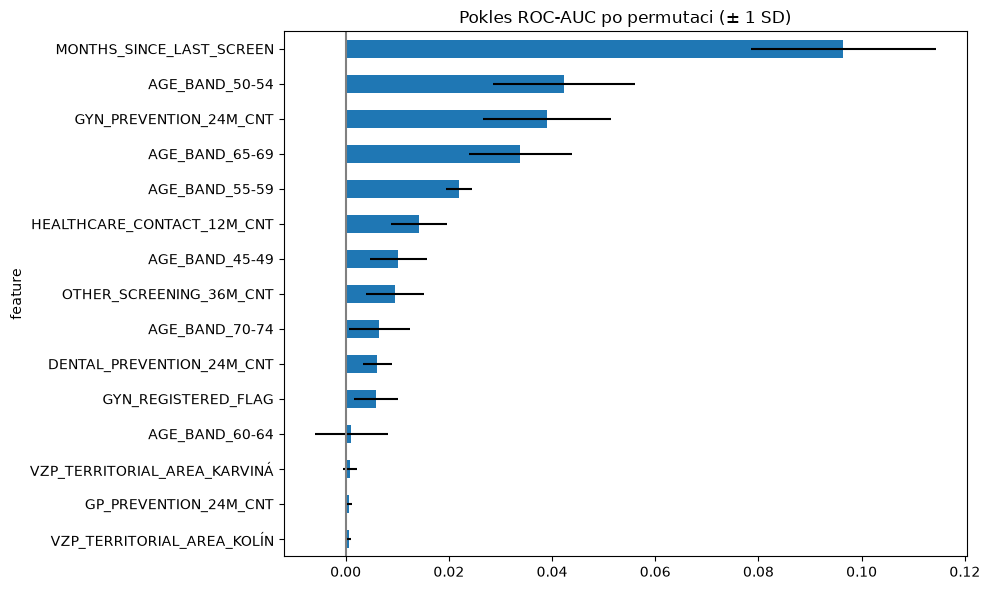

In [8]:
xa_native = xa.native_importance(final_best_model, xa_X.columns)
xa_permutation = xa.permutation_table(final_best_model, xa_X, xa_y, repeats=XA_REPEATS, seed=XA_SEED)
xa_grouped = xa.permutation_table(final_best_model, xa_X, xa_y, groups=xa_groups, repeats=XA_REPEATS, seed=XA_SEED)
display(xa_native.head(15).to_frame(), xa_permutation.head(20), xa_grouped.head(20))
xa_plot = xa_permutation.head(15).iloc[::-1]
xa_plot.auc_drop.plot.barh(xerr=xa_plot.auc_std, figsize=(10, 6), title='Pokles ROC-AUC po permutaci (± 1 SD)')
plt.axvline(0, color='gray')
plt.tight_layout()
plt.show()

### 7.2 SHAP: globální pořadí, směr efektu, stabilita a jednotlivé klientky
Bar a beeswarm shrnují celý vzorek; dependence zobrazuje dva nejdůležitější vstupy. Waterfall vysvětluje nejvyšší a nejnižší predikované riziko neúčasti. `top10_frequency` je podíl bootstrapů, ve kterých byl vstup v TOP 10. SHAP používá výchozí stromový background (tree-path-dependent), nikoli kauzální interpretaci. Absolutní SHAP měří velikost příspěvku, nikoli automaticky jeho směr. Podmíněný efekt může mít pro různé klientky opačné znaménko.

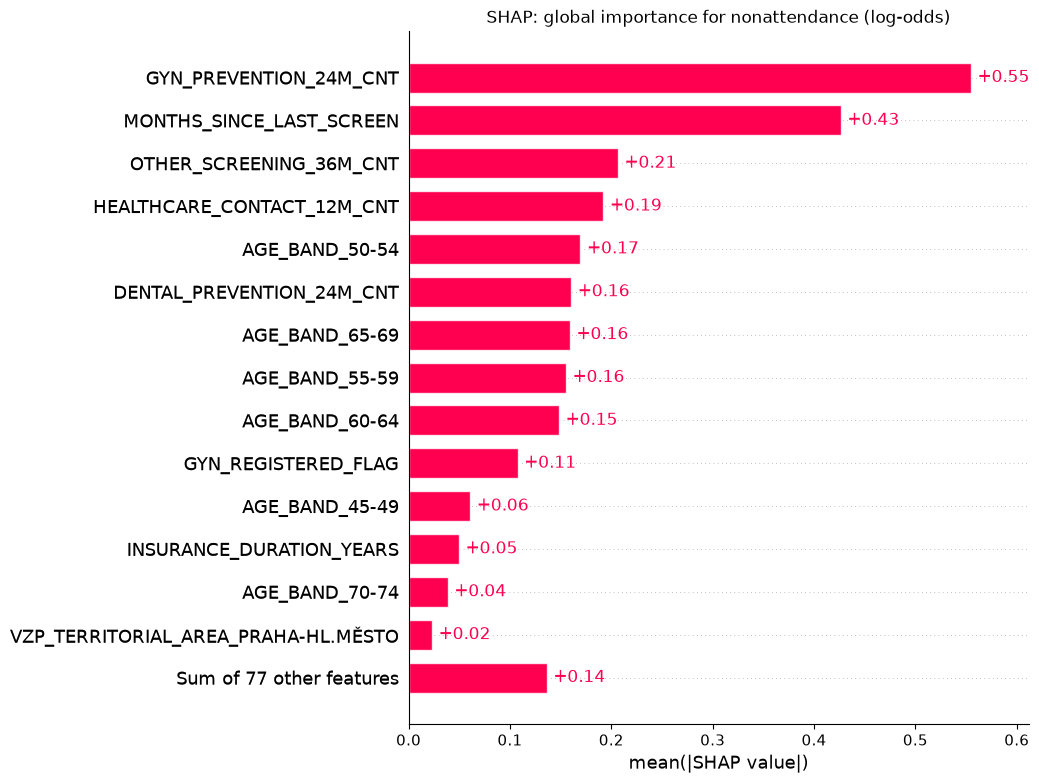

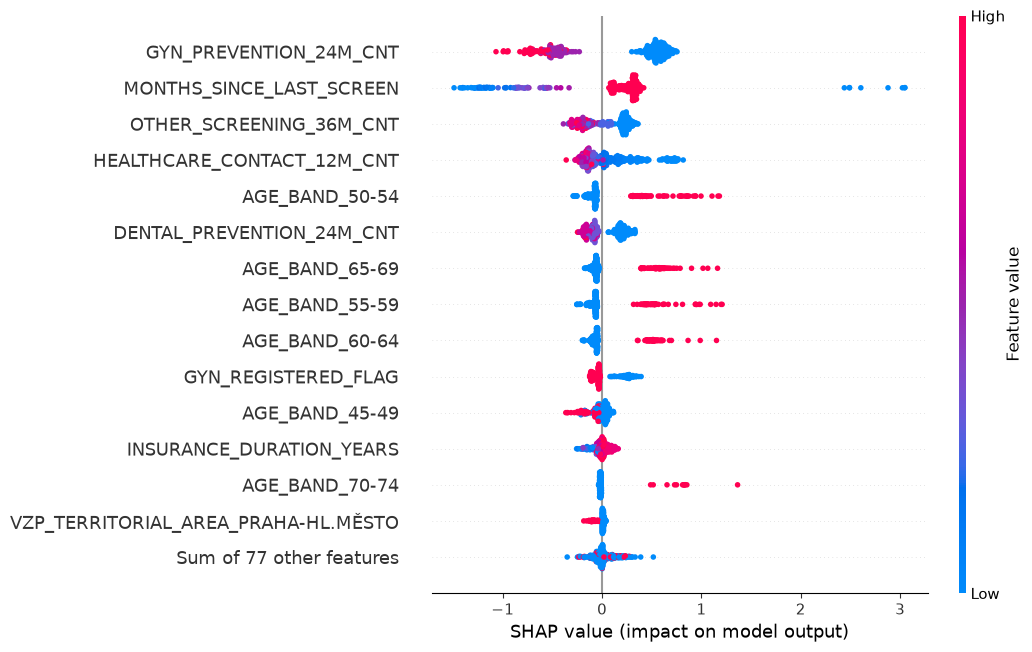

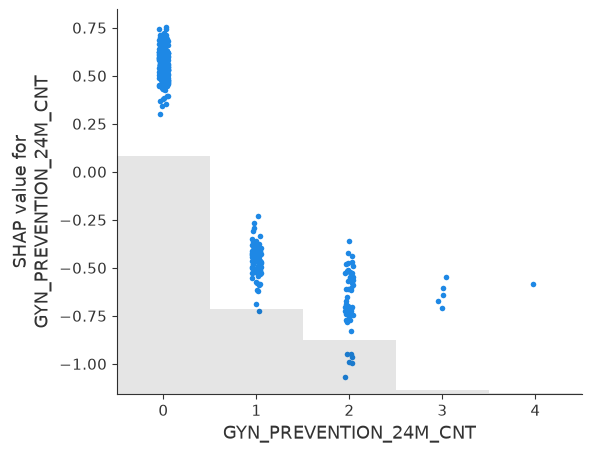

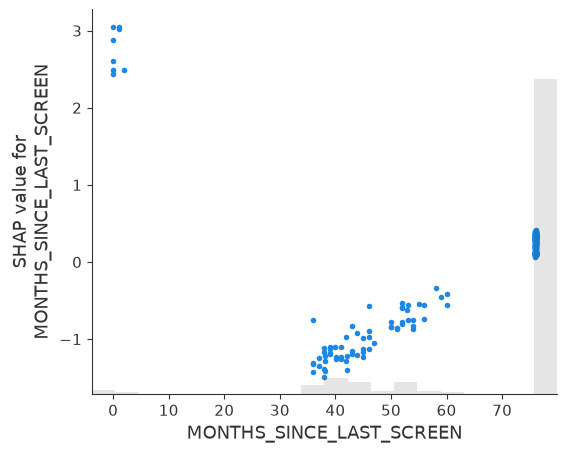

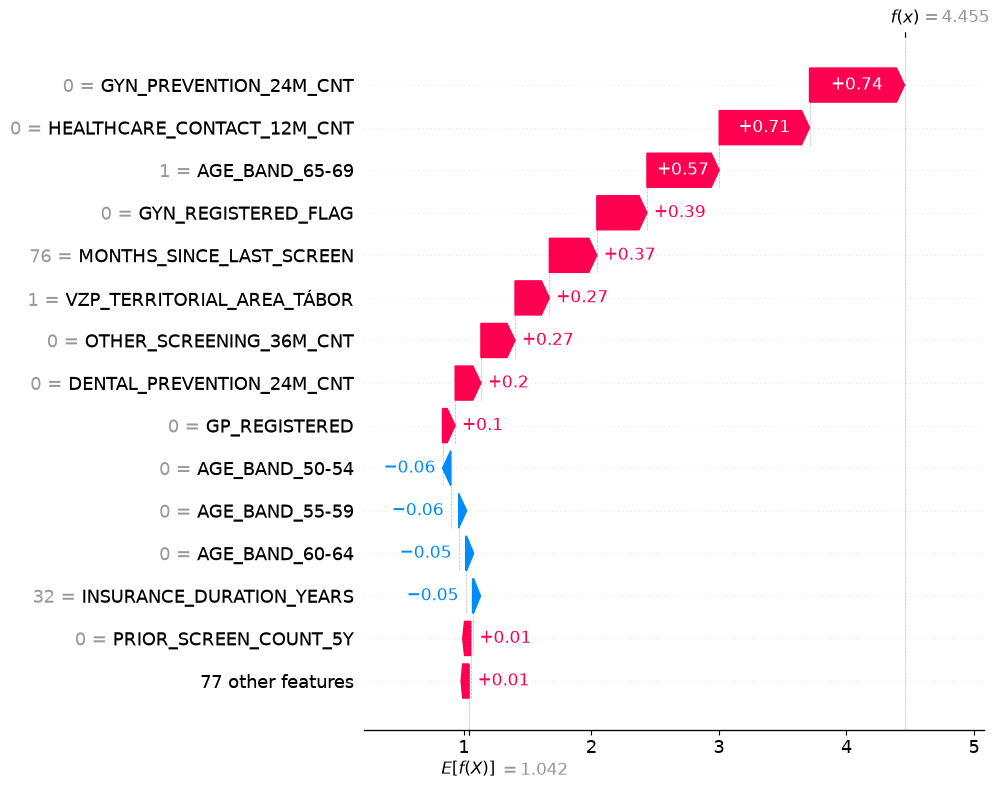

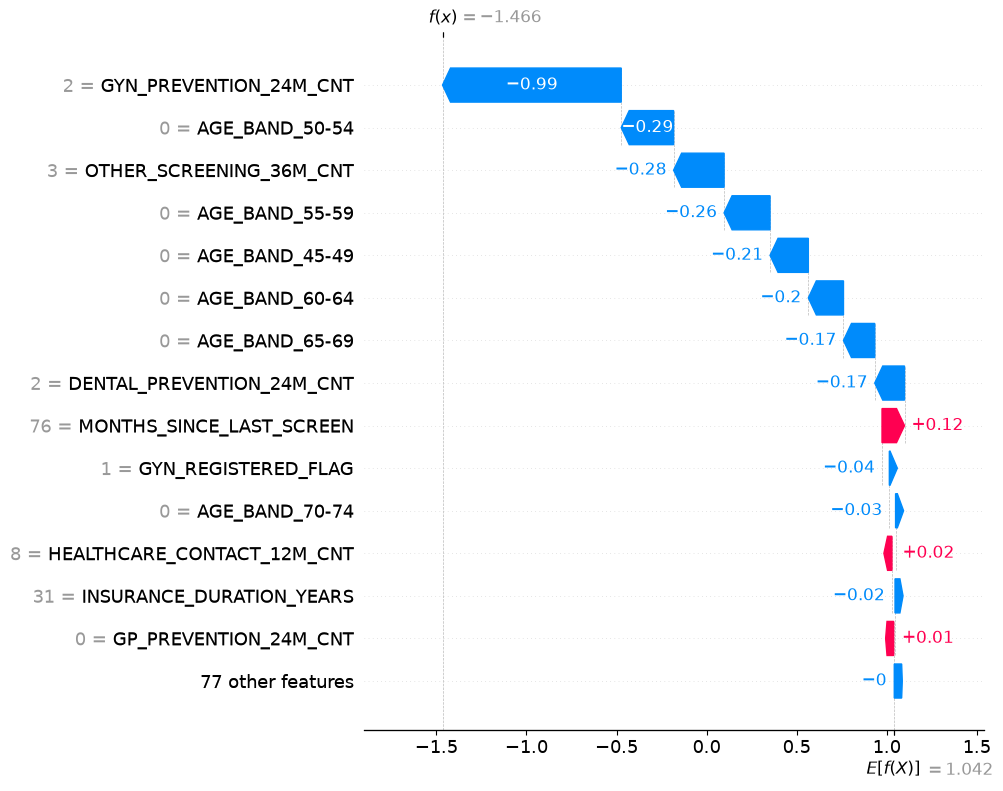

,mean_abs_shap,bootstrap_q025,bootstrap_q975,top10_frequency
GYN_PREVENTION_24M_CNT,0.554795,0.541379,0.567428,1.0
MONTHS_SINCE_LAST_SCREEN,0.426352,0.379701,0.475038,1.0
OTHER_SCREENING_36M_CNT,0.206443,0.198863,0.214356,1.0
HEALTHCARE_CONTACT_12M_CNT,0.192088,0.177720,0.209827,1.0
AGE_BAND_50-54,0.169511,0.148317,0.189429,1.0
DENTAL_PREVENTION_24M_CNT,0.160352,0.154852,0.167050,1.0
AGE_BAND_65-69,0.159105,0.139655,0.183103,1.0
AGE_BAND_55-59,0.155213,0.138954,0.179516,1.0
AGE_BAND_60-64,0.148398,0.130684,0.165738,1.0
GYN_REGISTERED_FLAG,0.107503,0.100174,0.116597,1.0


,row,feature,value,risk_shap_logodds,p_nonattendance,abs_impact
0,661363,GYN_PREVENTION_24M_CNT,0.0,0.744785,0.988517,0.744785
1,661363,HEALTHCARE_CONTACT_12M_CNT,0.0,0.708223,0.988517,0.708223
2,661363,AGE_BAND_65-69,1.0,0.566433,0.988517,0.566433
3,661363,GYN_REGISTERED_FLAG,0.0,0.393066,0.988517,0.393066
4,661363,MONTHS_SINCE_LAST_SCREEN,76.0,0.372185,0.988517,0.372185
5,661363,VZP_TERRITORIAL_AREA_TÁBOR,1.0,0.269239,0.988517,0.269239
6,661363,OTHER_SCREENING_36M_CNT,0.0,0.267336,0.988517,0.267336
7,661363,DENTAL_PREVENTION_24M_CNT,0.0,0.201932,0.988517,0.201932
8,661363,GP_REGISTERED,0.0,0.099041,0.988517,0.099041
9,661363,AGE_BAND_50-54,0.0,-0.064705,0.988517,0.064705


In [9]:
xa_shap_table, xa_shap_values, xa_local_shap = xa.shap_analysis(final_best_model, xa_X, XA_BOOTSTRAP, XA_SEED)
display(xa_shap_table.head(20))
display(xa_local_shap.groupby('row', sort=False).head(10))

### 7.3 Jak se riziko mění: PDP, ICE, ALE a interakce
Vybereme tři nejdůležitější původní číselné vstupy s více než dvěma hodnotami (ne jednotlivé one-hot kategorie). PDP je průměr při přepsání vstupu všem klientkám; ICE ukazuje prvních 25 individuálních křivek. ALE průměruje lokální rozdíly v kvantilových intervalech a centruje je podle počtu pozorování. V tabulkách ALE je i počet pozorování pro odhalení řídkých intervalů. Interakce měří RMS neaditivní složky 2D PDP na omezeném gridu v jednotkách pravděpodobnosti. Nejde o statistický test a neprohledáváme všechny dvojice; interakce mimo vybrané vstupy mohou zůstat skryté. I aditivní logit model může vykazovat neaditivitu na pravděpodobnostní škále.

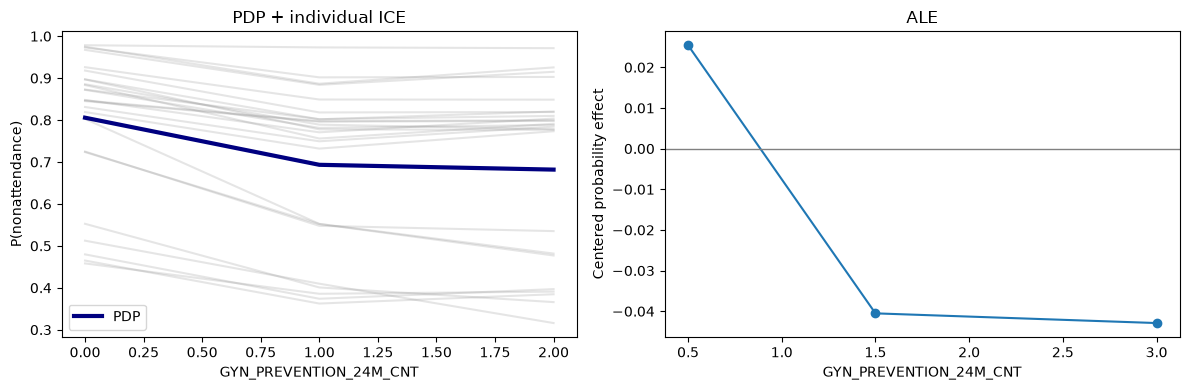

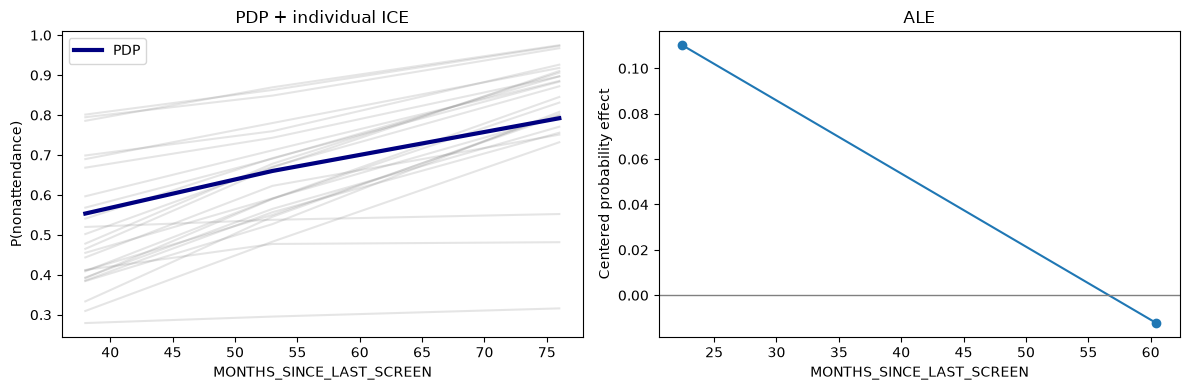

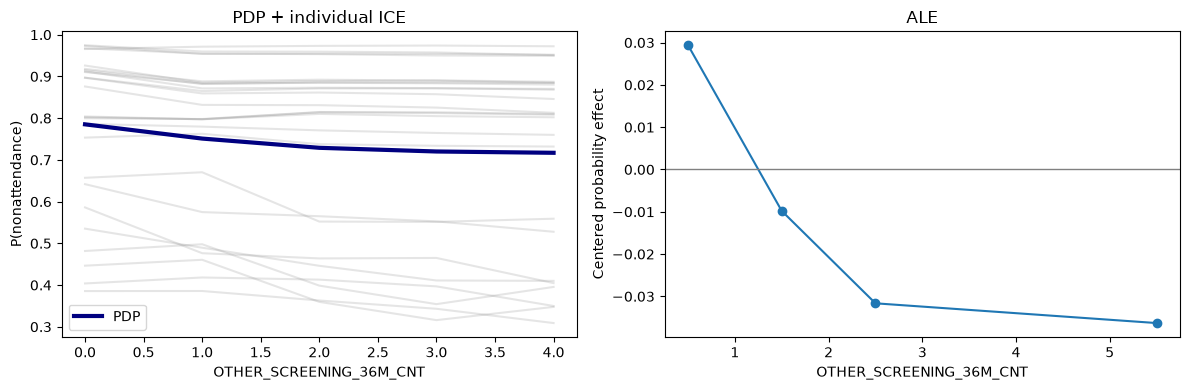

GYN_PREVENTION_24M_CNT


,value,ale,count
0,0.5,0.025435,248
1,1.5,-0.040510,89
2,3.0,-0.042895,63


MONTHS_SINCE_LAST_SCREEN


,value,ale,count
0,22.45,0.110188,40
1,60.45,-0.012243,360


OTHER_SCREENING_36M_CNT


,value,ale,count
0,0.5,0.029375,194
1,1.5,-0.009799,58
2,2.5,-0.031637,52
3,5.5,-0.036305,96


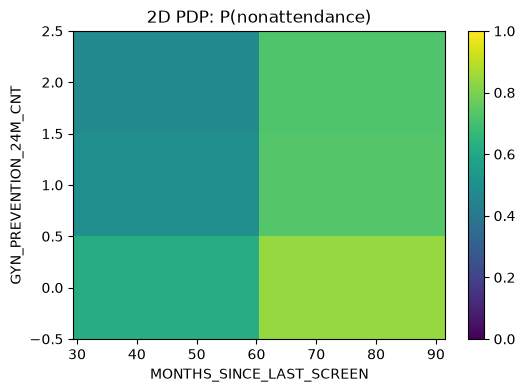

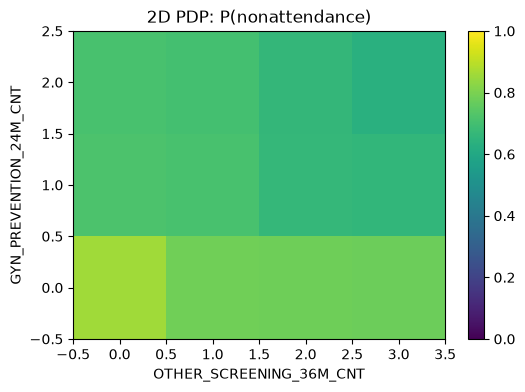

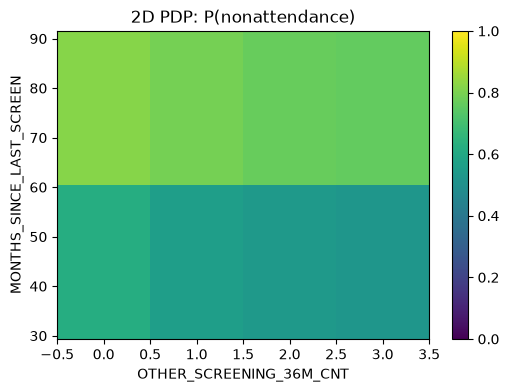

,first,second,pdp_nonadditivity_rms
1,GYN_PREVENTION_24M_CNT,OTHER_SCREENING_36M_CNT,0.011566
2,MONTHS_SINCE_LAST_SCREEN,OTHER_SCREENING_36M_CNT,0.006850
0,GYN_PREVENTION_24M_CNT,MONTHS_SINCE_LAST_SCREEN,0.006063


In [10]:
xa_effect_features = [col for col in xa_shap_table.index if col in X_num.columns and xa_X[col].nunique() > 2][:3]
if len(xa_effect_features) < 2:
    raise ValueError('Pro PDP/ALE a dvojice vyberte alespoň dva nekonstantní číselné vstupy.')
xa_effects = xa.effect_analysis(final_best_model, xa_X, xa_effect_features)
for xa_feature, xa_result in xa_effects.items():
    print(xa_feature)
    display(xa_result['ale'])
xa_interactions = xa.interaction_analysis(final_best_model, xa_X, xa_effect_features)
display(xa_interactions.sort_values('pdp_nonadditivity_rms', ascending=False))

### 7.4 Srozumitelná pravidla a lokální lineární vysvětlení
Malý strom se učí napodobit pravděpodobnosti původního modelu na trénovacích vstupech a měří věrnost na testu. Lokální Ridge surrogate využívá skupinově zachované hodnoty klientky a empirické trénovací hodnoty s váhami podle vzdálenosti. Koeficienty vyjadřují lokální změnu pravděpodobnosti na jednu trénovací směrodatnou odchylku, nikoli SHAP příspěvky. Věrnost měříme na oddělených perturbacích. **Nízké či záporné R² nebo vysoká MAE znamenají, že surrogate není věrným vysvětlením.** Lineární predikce může být i mimo [0, 1]; neořezáváme ji, aby se chyba nezakryla. Pro posouzení stability koeficientů opakujeme analýzu s pěti seedy.

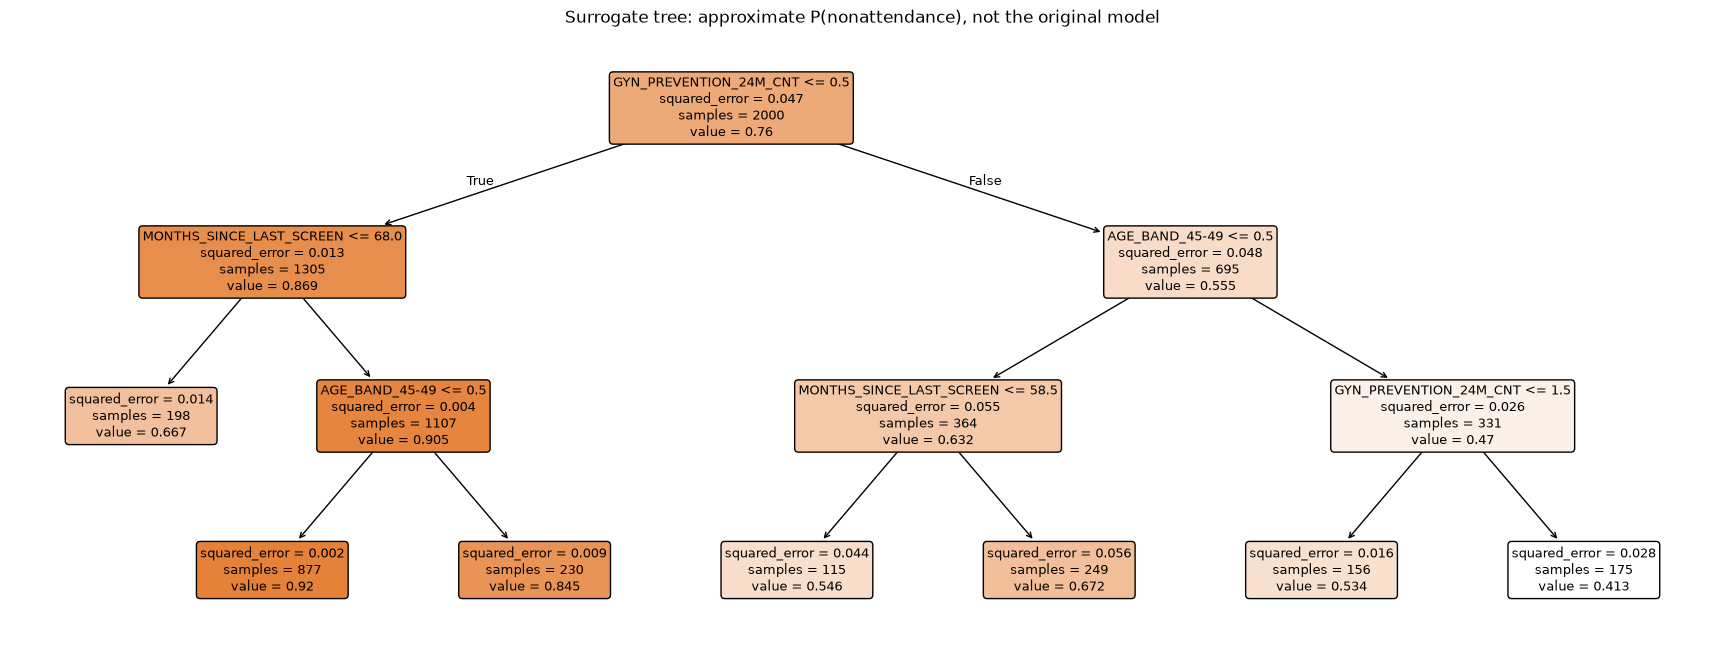

,věrnost
heldout_R2,0.675355
heldout_MAE,0.080093


|--- GYN_PREVENTION_24M_CNT <= 0.50
|   |--- MONTHS_SINCE_LAST_SCREEN <= 68.00
|   |   |--- value: [0.67]
|   |--- MONTHS_SINCE_LAST_SCREEN >  68.00
|   |   |--- AGE_BAND_45-49 <= 0.50
|   |   |   |--- value: [0.92]
|   |   |--- AGE_BAND_45-49 >  0.50
|   |   |   |--- value: [0.84]
|--- GYN_PREVENTION_24M_CNT >  0.50
|   |--- AGE_BAND_45-49 <= 0.50
|   |   |--- MONTHS_SINCE_LAST_SCREEN <= 58.50
|   |   |   |--- value: [0.55]
|   |   |--- MONTHS_SINCE_LAST_SCREEN >  58.50
|   |   |   |--- value: [0.67]
|   |--- AGE_BAND_45-49 >  0.50
|   |   |--- GYN_PREVENTION_24M_CNT <= 1.50
|   |   |   |--- value: [0.53]
|   |   |--- GYN_PREVENTION_24M_CNT >  1.50
|   |   |   |--- value: [0.41]



,mean_coefficient,SD,positive_fraction
NEVER_SCREENED_BEFORE_FLAG,0.104054,0.017751,1.0
AGE_BAND_65-69,0.069151,0.023024,1.0
AGE_BAND_60-64,0.062887,0.022176,1.0
AGE_BAND_55-59,0.062019,0.021532,1.0
MONTHS_SINCE_LAST_SCREEN,-0.057623,0.009623,0.0
AGE_BAND_50-54,0.056508,0.019355,1.0
GYN_PREVENTION_24M_CNT,-0.054313,0.006835,0.0
AGE_BAND_45-49,0.037615,0.027746,1.0
AGE_BAND_70-74,0.026664,0.010378,1.0
HEALTHCARE_CONTACT_12M_CNT,-0.022867,0.003326,0.0


,local_heldout_weighted_R2,local_heldout_weighted_MAE,patient_actual_probability,patient_surrogate_probability
0,0.675679,0.038326,0.988517,1.013023
1,0.668623,0.041929,0.988517,1.011322
2,0.472441,0.035288,0.988517,1.011587
3,0.710577,0.034115,0.988517,1.010259
4,0.687576,0.037377,0.988517,1.008108


In [11]:
xa_tree_fidelity, xa_rules, xa_tree = xa.global_surrogate(final_best_model, xa_train, xa_X)
display(xa_tree_fidelity.to_frame('věrnost'))
print(xa_rules)
xa_patient = xa_X.iloc[[int(np.argmax(xa_risk))]].copy()
xa_local_runs = [xa.local_surrogate(final_best_model, xa_train, xa_patient, xa_groups, seed=XA_SEED + i) for i in range(5)]
xa_local_coefficients = pd.concat([result[0].rename(i) for i, result in enumerate(xa_local_runs)], axis=1)
xa_local_stability = pd.DataFrame({'mean_coefficient': xa_local_coefficients.mean(axis=1), 'SD': xa_local_coefficients.std(axis=1), 'positive_fraction': (xa_local_coefficients > 0).mean(axis=1)})
display(xa_local_stability.loc[xa_local_stability.mean_coefficient.abs().sort_values(ascending=False).index].head(20))
display(pd.DataFrame([result[1] for result in xa_local_runs]))

### 7.5 Pozorované scénáře a shoda metod
Najdeme nejbližší skutečné trénovací profily s nižším predikovaným rizikem a ukážeme všechny rozdíly. Pokud žádný neexistuje, výsledek je výslovně prázdný. **Nejde o optimalizovaný counterfactual ani proveditelný zásah:** lišit se může věk, region či historie, které nelze změnit; potřebná je doménová kontrola. Syntetické counterfactualy bez těchto omezení by byly zavádějící.

Konsenzus porovnává pořadí, nikoli nesouměřitelné velikosti skóre. Permutační AUC a log-loss jsou příbuzné, nejsou dva nezávislé hlasy. Vysoký rozptyl pořadí je důvod k prozkoumání korelací a interakcí, nikoli k automatickému odstranění vstupu. Skupinové pořadí posuzujte samostatně.

Pro závěrečnou zprávu: uveďte TOP faktory v konsenzu i skupinách, jejich SHAP směr pro konkrétní klientku, nejistotu pořadí, tvar ALE, nejvýraznější testovanou interakci a věrnost obou surrogate metod. Klinické závěry bez doménového ověření nevyvozujte.

In [12]:
xa_scenarios = xa.observed_scenarios(final_best_model, xa_train, xa_patient)
if xa_scenarios.empty:
    print('Ve vzorku trénovacích profilů není žádný profil s nižším rizikem.')
display(xa_scenarios)
xa_consensus = xa.consensus_table(xa_native, xa_permutation, xa_shap_table)
display(xa_consensus.head(20))
display(xa_train[xa_consensus.index[:12]].corr(method='spearman').round(2))
# Volitelný export obsahuje jen globální agregace, ne individuální zdravotní údaje.
# xa_consensus.to_csv('explainability_global_consensus.csv', index_label='feature')

,p_nonattendance,standardized_distance,risk_difference,"changed_values_(patient,reference)"
545724,0.905248,0.596623,-0.083269,"{'HEALTHCARE_CONTACT_12M_CNT': (0.0, 47), 'INS..."
751631,0.934333,0.855681,-0.054184,"{'HEALTHCARE_CONTACT_12M_CNT': (0.0, 1), 'INSU..."
875208,0.974220,0.871207,-0.014297,"{'HEALTHCARE_CONTACT_12M_CNT': (0.0, 2), 'INSU..."
736230,0.900508,0.881064,-0.088008,"{'HEALTHCARE_CONTACT_12M_CNT': (0.0, 38), 'INS..."
678899,0.483567,0.938565,-0.504950,"{'HEALTHCARE_CONTACT_12M_CNT': (0.0, 5), 'GP_R..."


,native,permutation_auc,permutation_logloss,shap,native_rank,permutation_auc_rank,permutation_logloss_rank,shap_rank,mean_rank,rank_spread
MONTHS_SINCE_LAST_SCREEN,0.082908,0.096483,0.064440,0.426352,2.0,1.0,1.0,2.0,1.50,1.0
GYN_PREVENTION_24M_CNT,0.315080,0.039011,0.025664,0.554795,1.0,3.0,5.0,1.0,2.50,4.0
AGE_BAND_50-54,0.073964,0.042268,0.045823,0.169511,3.0,2.0,2.0,5.0,3.00,3.0
AGE_BAND_55-59,0.062646,0.021973,0.027091,0.155213,5.0,5.0,3.0,8.0,5.25,5.0
AGE_BAND_65-69,0.028152,0.033840,0.025987,0.159105,7.0,4.0,4.0,7.0,5.50,3.0
AGE_BAND_45-49,0.073285,0.010213,0.022212,0.060769,4.0,7.0,6.0,11.0,7.00,7.0
OTHER_SCREENING_36M_CNT,0.025226,0.009569,0.006856,0.206443,8.0,8.0,9.0,3.0,7.00,6.0
HEALTHCARE_CONTACT_12M_CNT,0.006372,0.014264,0.009588,0.192088,17.0,6.0,7.0,4.0,8.50,13.0
DENTAL_PREVENTION_24M_CNT,0.020571,0.006167,0.001746,0.160352,10.0,10.0,12.0,6.0,9.50,6.0
AGE_BAND_60-64,0.045891,0.001116,0.002494,0.148398,6.0,12.0,11.0,9.0,9.50,6.0


,MONTHS_SINCE_LAST_SCREEN,GYN_PREVENTION_24M_CNT,AGE_BAND_50-54,AGE_BAND_55-59,AGE_BAND_65-69,AGE_BAND_45-49,OTHER_SCREENING_36M_CNT,HEALTHCARE_CONTACT_12M_CNT,DENTAL_PREVENTION_24M_CNT,AGE_BAND_60-64,GYN_REGISTERED_FLAG,AGE_BAND_70-74
MONTHS_SINCE_LAST_SCREEN,1.00,-0.09,-0.12,-0.03,-0.04,0.16,-0.14,-0.16,-0.07,-0.04,-0.13,-0.04
GYN_PREVENTION_24M_CNT,-0.09,1.00,0.01,-0.08,-0.22,0.32,0.61,0.29,0.31,-0.17,0.33,-0.07
AGE_BAND_50-54,-0.12,0.01,1.00,-0.18,-0.20,-0.26,-0.04,-0.03,-0.01,-0.19,0.02,-0.07
AGE_BAND_55-59,-0.03,-0.08,-0.18,1.00,-0.20,-0.27,-0.01,0.01,-0.06,-0.19,-0.03,-0.07
AGE_BAND_65-69,-0.04,-0.22,-0.20,-0.20,1.00,-0.30,-0.11,0.02,-0.07,-0.21,-0.13,-0.08
AGE_BAND_45-49,0.16,0.32,-0.26,-0.27,-0.30,1.00,0.11,-0.02,0.14,-0.28,0.16,-0.10
OTHER_SCREENING_36M_CNT,-0.14,0.61,-0.04,-0.01,-0.11,0.11,1.00,0.30,0.24,-0.02,0.24,-0.00
HEALTHCARE_CONTACT_12M_CNT,-0.16,0.29,-0.03,0.01,0.02,-0.02,0.30,1.00,0.16,-0.00,0.18,0.01
DENTAL_PREVENTION_24M_CNT,-0.07,0.31,-0.01,-0.06,-0.07,0.14,0.24,0.16,1.00,-0.06,0.24,-0.01
AGE_BAND_60-64,-0.04,-0.17,-0.19,-0.19,-0.21,-0.28,-0.02,-0.00,-0.06,1.00,-0.08,-0.07
